# 1. The sphere
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/1_sphere.ipynb)

We begin with the familiar domain of the unit sphere, for which the Mie series gives the exact scattered field (Section 3.1 of the paper). A plane wave impinges from the positive $z$-axis, polarised along $y$, with $k = 2\pi$, so the sphere is two wavelengths across.

The MFS approximates the scattered field by $N$ electric dipoles on a smaller sphere of radius $R_s$,
$$\mathbf{E}_N(\mathbf{x}) = \sum_{j=1}^N \mathbf{G}(\mathbf{x}, \mathbf{y}_j)\, \boldsymbol{\alpha}_j,$$
and chooses the coefficients so that the tangential part of the total field vanishes, in the least-squares sense, at $M = 2N$ points of the surface.

In [1]:
# On Colab: get the code and the data (this cell does nothing when run locally)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        !git clone -q https://github.com/sap6/MFS /content/MFS
    sys.path.insert(0, "/content/MFS")            # numpy, scipy, numba and matplotlib come with Colab
    os.chdir("/content/MFS/notebooks")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import core, mie, sphere

k = 2 * np.pi                  # wavenumber: the sphere is two wavelengths across
d, p = core.wave()             # propagation direction (0, 0, -1) and polarisation (0, 1, 0)

## One solve
Here is all of it: source and boundary points, the matrix of tangential dipole fields, and a least-squares solve (`mfs/sphere.py`).

In [3]:
# 400 dipoles (1200 unknowns) on the sphere of radius 0.5
y, alpha = sphere.solve(400, k, R=0.5)

# Compare with the Mie series on the sphere of radius 2
pts = 2.0 * core.fibonacci(400)
E_mfs = core.field(pts, y, alpha, k)
E_mie = mie.scattered_field(pts, k, d, p)
print(f"relative error against Mie: {core.rel(E_mfs, E_mie):.1e}")

relative error against Mie: 2.0e-09


## Convergence
Plotted against $\sqrt{N}$ the errors lie on straight lines, so the error behaves like $\exp(-c\sqrt{N})$. Every source radius converges, because the continued field of the sphere is singular only at the centre, but a smaller radius converges faster until the coefficients grow so large that rounding errors take over.

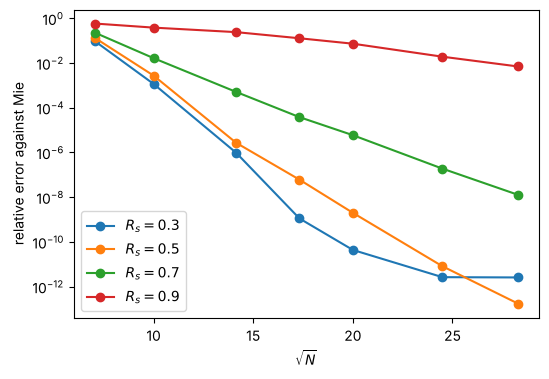

In [4]:
Ns = [50, 100, 200, 300, 400, 600, 800]
fig, ax = plt.subplots(figsize=(6, 4))
for R in (0.3, 0.5, 0.7, 0.9):
    err = [core.rel(core.field(pts, *sphere.solve(N, k, R), k), E_mie) for N in Ns]
    ax.semilogy(np.sqrt(Ns), err, "o-", label=f"$R_s = {R}$")
ax.set(xlabel=r"$\sqrt{N}$", ylabel="relative error against Mie")
ax.legend()
plt.show()

## The field near the surface
The MFS field is a finite sum of dipole fields, so it is evaluated in the same way at every point outside the body, even very close to the surface (Figure 11 of the paper).

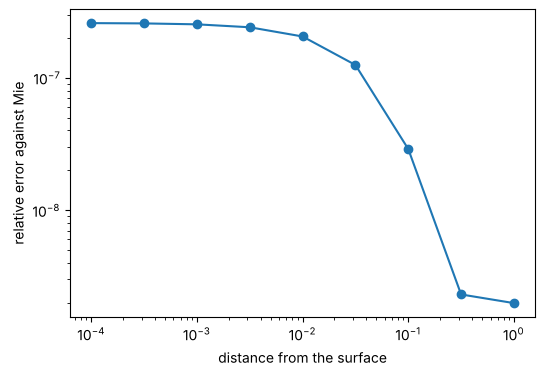

In [5]:
# Error of the field on spheres at a distance delta from the surface, for N = 400
delta = np.logspace(-4, 0, 9)
err = [core.rel(core.field((1 + dl) * core.fibonacci(200), y, alpha, k),
                mie.scattered_field((1 + dl) * core.fibonacci(200), k, d, p)) for dl in delta]
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(delta, err, "o-")
ax.set(xlabel="distance from the surface", ylabel="relative error against Mie")
plt.show()